# Exploratory data analysis: groundwater quality (Telangana, post-monsoon 2018)

Exercise from the ITMO course *Artificial Intelligence in a Chemist's Work*. The dataset (374 samples) contains location,
groundwater level, pH, conductivity, total dissolved solids (TDS), major ions, calculated indices and the irrigation-water class.
Figures are interactive plotly charts; static images are stored so that they display on GitHub.

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
from scipy import stats
from matplotlib import pyplot as plt
import seaborn as sns

colors = ['#D8AF65', '#AC3822', '#881C43', '#6B3F63', '#5E6E85']

## Step 1. Data overview

In [ ]:
wat = pd.read_csv('data/ground_water_quality_2018_post.csv')
wat.head()

,sno,district,mandal,village,lat_gis,long_gis,gwl,season,pH,E.C,...,SO4,Na,K,Ca,Mg,T.H,SAR,Classification,RSC meq / L,Classification.1
0,1,ADILABAD,Adilabad,Adilabad,19.668300,78.524700,5.09,postmonsoon 2018,8.28,745,...,46.0,49.0,4.0,48,38.896,279.934211,1.273328,C2S1,-1.198684,P.S.
1,2,ADILABAD,Bazarhatnur,Bazarhatnur,19.458888,78.350833,5.10,postmonsoon 2018,8.29,921,...,68.0,42.0,5.0,56,63.206,399.893092,0.913166,C3S1,-3.397862,P.S.
2,3,ADILABAD,Gudihatnoor,Gudihatnoor,19.525555,78.512222,4.98,postmonsoon 2018,7.69,510,...,44.0,45.0,2.0,24,38.896,219.934211,1.319284,C2S1,-0.398684,P.S.
3,4,ADILABAD,Jainath,Jainath,19.730555,78.640000,5.75,postmonsoon 2018,8.09,422,...,35.0,27.0,1.0,32,19.448,159.967105,0.928155,C2S1,0.000658,P.S.
4,5,ADILABAD,Narnoor,Narnoor,19.495665,78.852654,2.15,postmonsoon 2018,8.21,2321,...,280.0,298.0,5.0,56,92.378,519.843750,5.682664,C4S2,-4.396875,P.S.


In [ ]:
wat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sno               374 non-null    int64  
 1   district          374 non-null    object 
 2   mandal            374 non-null    object 
 3   village           374 non-null    object 
 4   lat_gis           374 non-null    float64
 5   long_gis          374 non-null    float64
 6   gwl               371 non-null    float64
 7   season            374 non-null    object 
 8   pH                374 non-null    float64
 9   E.C               374 non-null    int64  
 10  TDS               374 non-null    float64
 11  CO3               374 non-null    int64  
 12  HCO3              374 non-null    float64
 13  Cl                374 non-null    int64  
 14  F                 374 non-null    float64
 15  NO3               374 non-null    float64
 16  SO4               374 non-null    float64
 1

In [ ]:
# Missing values per column
wat.isna().sum()

,0
sno,0
district,0
mandal,0
village,0
lat_gis,0
long_gis,0
gwl,3
season,0
pH,0
E.C,0


In [ ]:
# 1. Drop columns that carry no information
#    sno: row number; season: the same value ('postmonsoon 2018') in every row;
#    Classification.1: a second label column, not used here
cols_to_drop = ['sno', 'season', 'Classification.1']
wat = wat.drop(columns=cols_to_drop, errors='ignore')

# 2. Drop CO3 if it contains only zeros
if wat['CO3'].sum() == 0:
    wat = wat.drop(columns=['CO3'])

print(wat.dtypes)

district           object
mandal             object
village            object
lat_gis           float64
long_gis          float64
gwl               float64
pH                float64
E.C                 int64
TDS               float64
CO3                 int64
HCO3              float64
Cl                  int64
F                 float64
NO3               float64
SO4               float64
Na                float64
K                 float64
Ca                  int64
Mg                float64
T.H               float64
SAR               float64
Classification     object
RSC  meq  / L     float64
dtype: object


### Duplicates

In [ ]:
wat = wat.drop_duplicates()

In [ ]:
# Villages that occur more than once
print(wat['village'].value_counts().head(7))

village
Kanchanapalli    2
Kallur           2
Khanapur         2
Angadipet        2
Kodur            2
Dharoor          2
Mupkal           1
Name: count, dtype: int64


In [ ]:
# Duplicates by the full location (district, mandal, village)
location_duplicates = wat.duplicated(subset=['district', 'mandal', 'village'], keep=False)
print(wat[location_duplicates].sort_values(by=['district', 'village']))

Empty DataFrame
Columns: [district, mandal, village, lat_gis, long_gis, gwl, pH, E.C, TDS, CO3, HCO3, Cl, F, NO3 , SO4, Na, K, Ca, Mg, T.H, SAR, Classification, RSC  meq  / L]
Index: []

[0 rows x 23 columns]


## Step 2. Univariate analysis

In [ ]:
wat.describe()

,lat_gis,long_gis,gwl,pH,E.C,TDS,CO3,HCO3,Cl,F,NO3,SO4,Na,K,Ca,Mg,T.H,SAR,RSC meq / L
count,374.000000,374.000000,371.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,17.701195,78.790172,12.074340,7.893182,1310.601604,838.785027,7.058824,277.676970,187.005348,1.237570,73.766746,44.068182,122.495842,7.832005,73.540107,50.480107,391.200592,2.899550,-2.129246
std,0.852885,0.818041,8.533991,0.453799,761.346975,487.262064,18.478645,125.746737,175.897896,0.824399,85.955538,54.500824,103.606183,20.979184,55.003215,35.990466,237.068468,3.106553,4.406282
min,15.896441,77.444000,0.570000,6.600000,212.000000,135.680000,0.000000,30.000000,10.000000,0.070000,0.442900,1.000000,5.076154,0.160000,8.000000,4.862000,39.991776,0.201487,-30.870545
25%,17.133500,78.185767,5.115000,7.580000,766.250000,490.400000,0.000000,186.523010,60.000000,0.692250,20.630081,15.000000,58.076763,1.932500,40.000000,24.310000,239.936266,1.495094,-3.821711
50%,17.632227,78.583022,10.000000,7.920000,1173.500000,751.040000,0.000000,263.842574,140.000000,1.060000,46.403841,24.000000,96.697517,3.000000,56.000000,43.758000,339.930099,2.133858,-1.260949
75%,18.352612,79.343660,16.575000,8.217500,1666.250000,1066.400000,0.000000,353.548878,260.000000,1.545000,101.066760,43.562500,153.622703,5.990000,96.000000,63.206000,499.923931,3.339268,0.014516
max,19.730555,80.920000,43.170000,10.440000,5440.000000,3481.600000,100.000000,970.588963,1500.000000,4.970000,735.214000,453.000000,714.800195,213.700000,488.000000,228.514000,2099.638158,31.079547,17.412602


### Distribution of the target variable, TDS

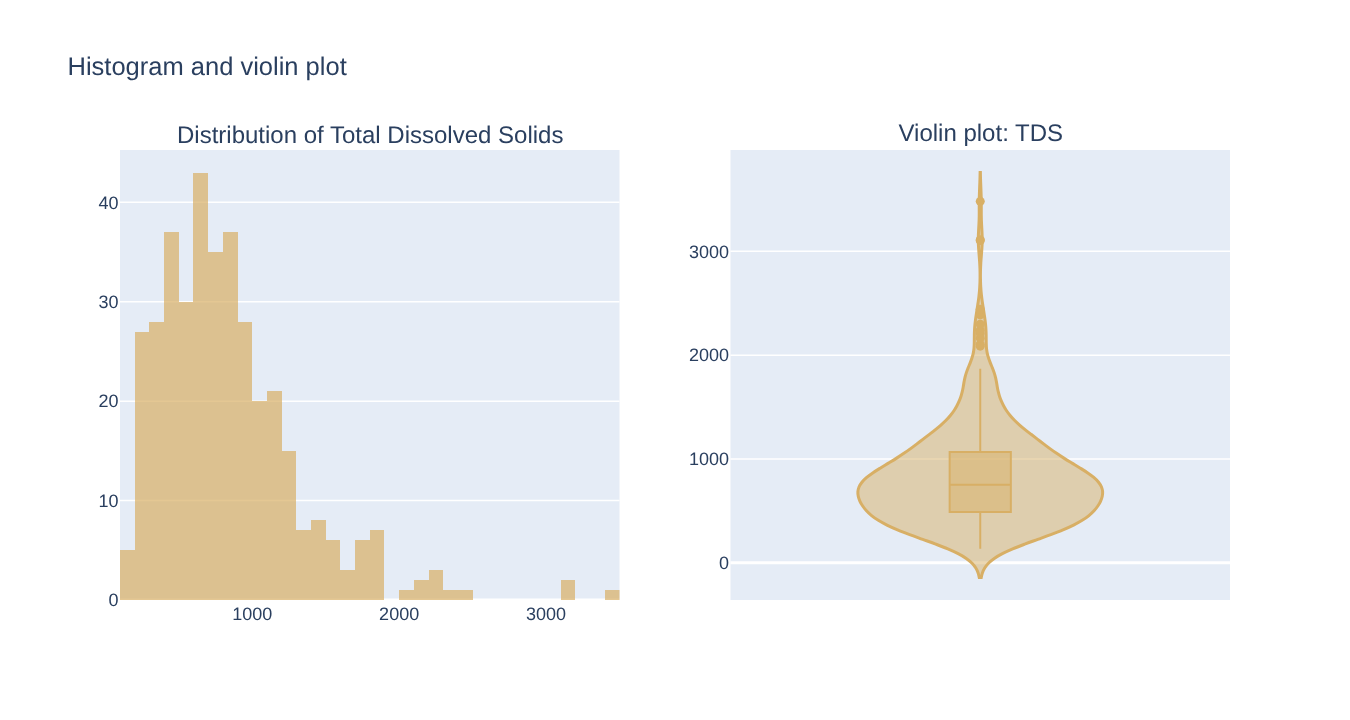

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution of Total Dissolved Solids', 'Violin plot: TDS'])
hist_fig = px.histogram(wat, x="TDS", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="TDS", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

Normality test

In [ ]:
# Anderson–Darling test against the normal distribution
result = stats.anderson(wat['TDS'], dist='norm')
print('Test statistic:', result.statistic)
print('Critical values:', result.critical_values)
print('Significance levels, %:', result.significance_level)

# critical_values[2] corresponds to the 5 % significance level
if result.statistic < result.critical_values[2]:
    print("Normality is not rejected.")
else:
    print("Normality is rejected: the data do not follow a normal distribution.")

Test statistic: 8.431168593308485
Critical values: [0.57  0.649 0.779 0.908 1.081]
Significance levels, %: [15.  10.   5.   2.5  1. ]
Normality is rejected: the data do not follow a normal distribution.


**Conclusion:** the TDS distribution is not normal.

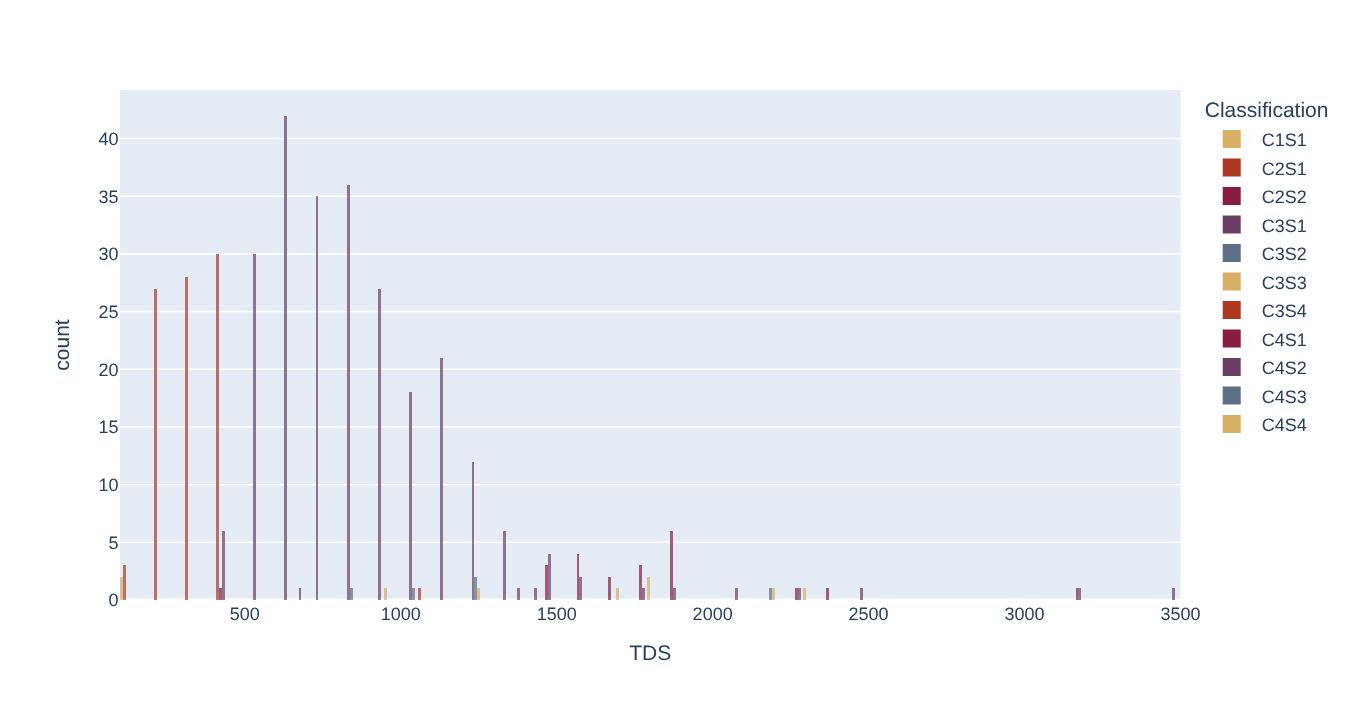

In [ ]:
wat_sort_group = wat.sort_values(by='Classification')
hist_fig = px.histogram(wat_sort_group, x="TDS", color='Classification', nbins=60,
                        color_discrete_sequence=colors, opacity=0.7)
hist_fig.show()

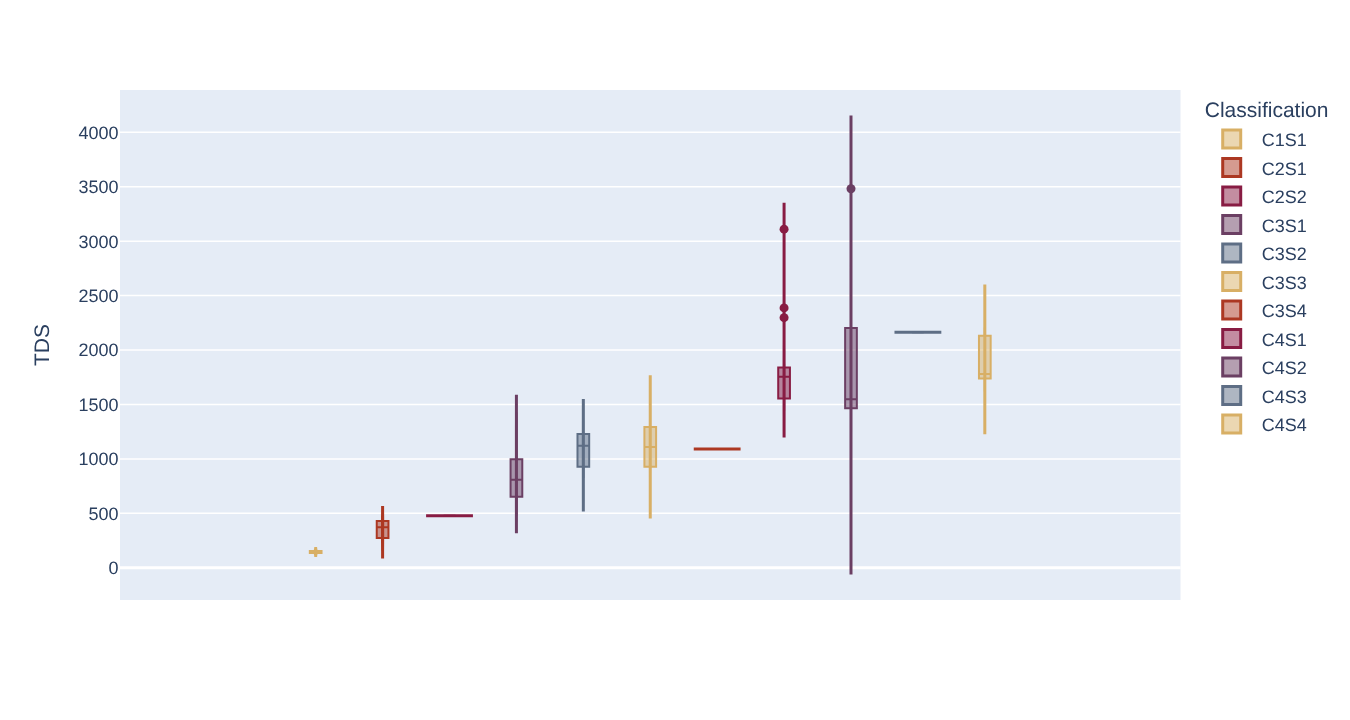

In [ ]:
violin_fig = px.violin(wat_sort_group, y="TDS", color='Classification', color_discrete_sequence=colors, box=True)
violin_fig.show()

**Conclusion:** TDS largely determines the water class.

In [ ]:
# Kruskal–Wallis test: does TDS differ between water classes?
statistic, p_value = stats.kruskal(*[wat[wat['Classification'] == c]['TDS']
                                     for c in ['C3S1', 'C2S1', 'C4S1', 'C4S2', 'C3S2', 'C4S4', 'C3S3', 'C4S3', 'C1S1']])
print(f"Statistic: {statistic:.2f}")
print(f"p-value: {p_value:.2f}")

if p_value > 0.05:
    print("No statistically significant difference between the groups")
else:
    print("There is a statistically significant difference between the groups")

Statistic: 263.89
p-value: 0.00
There is a statistically significant difference between the groups


### Continuous variables

pH, EC, TDS, total hardness (T.H), sodium adsorption ratio (SAR) and residual sodium carbonate (RSC, meq/L).

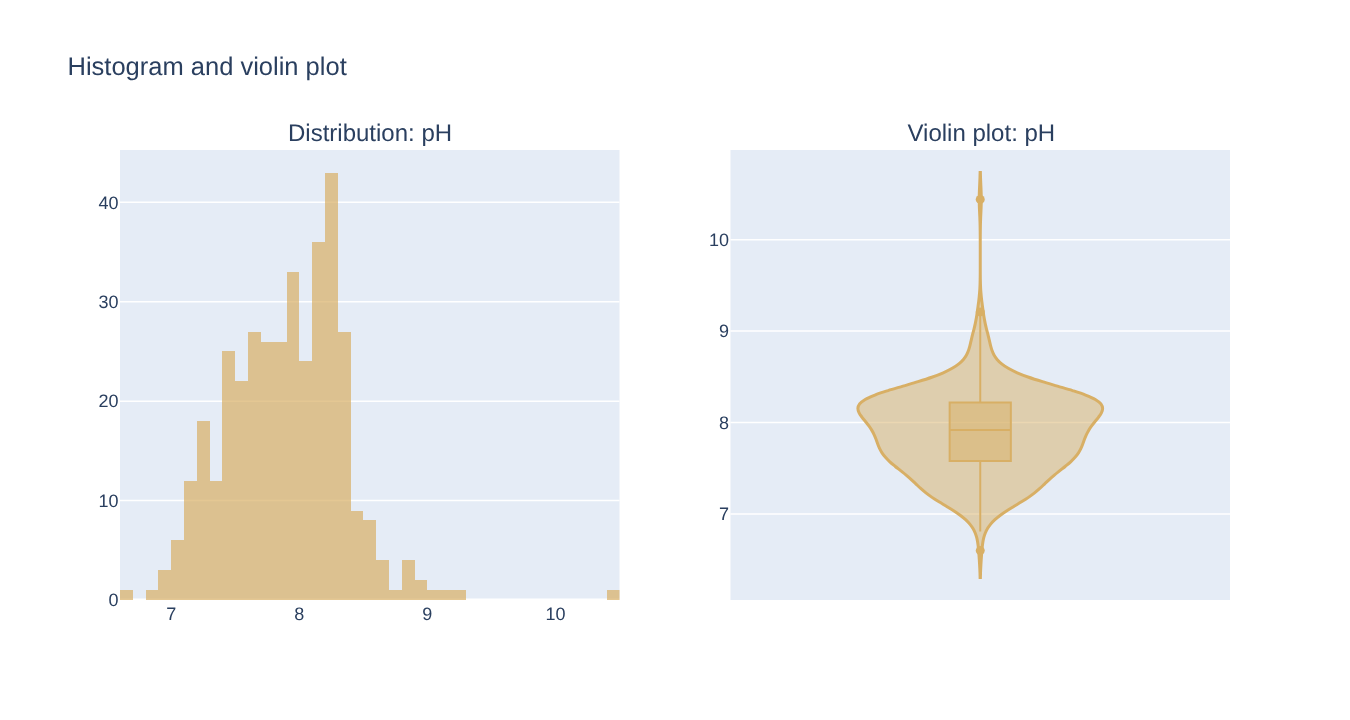

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution: pH', 'Violin plot: pH'])
hist_fig = px.histogram(wat, x="pH", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="pH", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

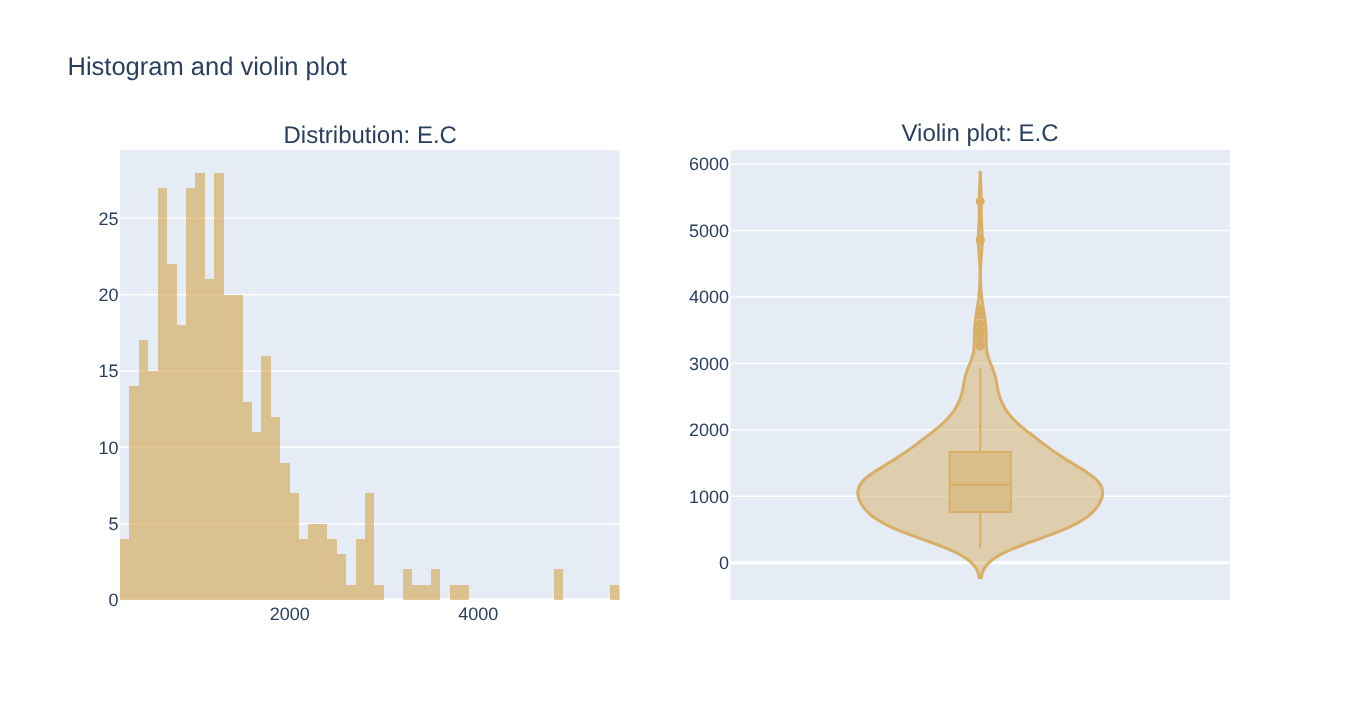

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution: E.C', 'Violin plot: E.C'])
hist_fig = px.histogram(wat, x="E.C", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="E.C", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

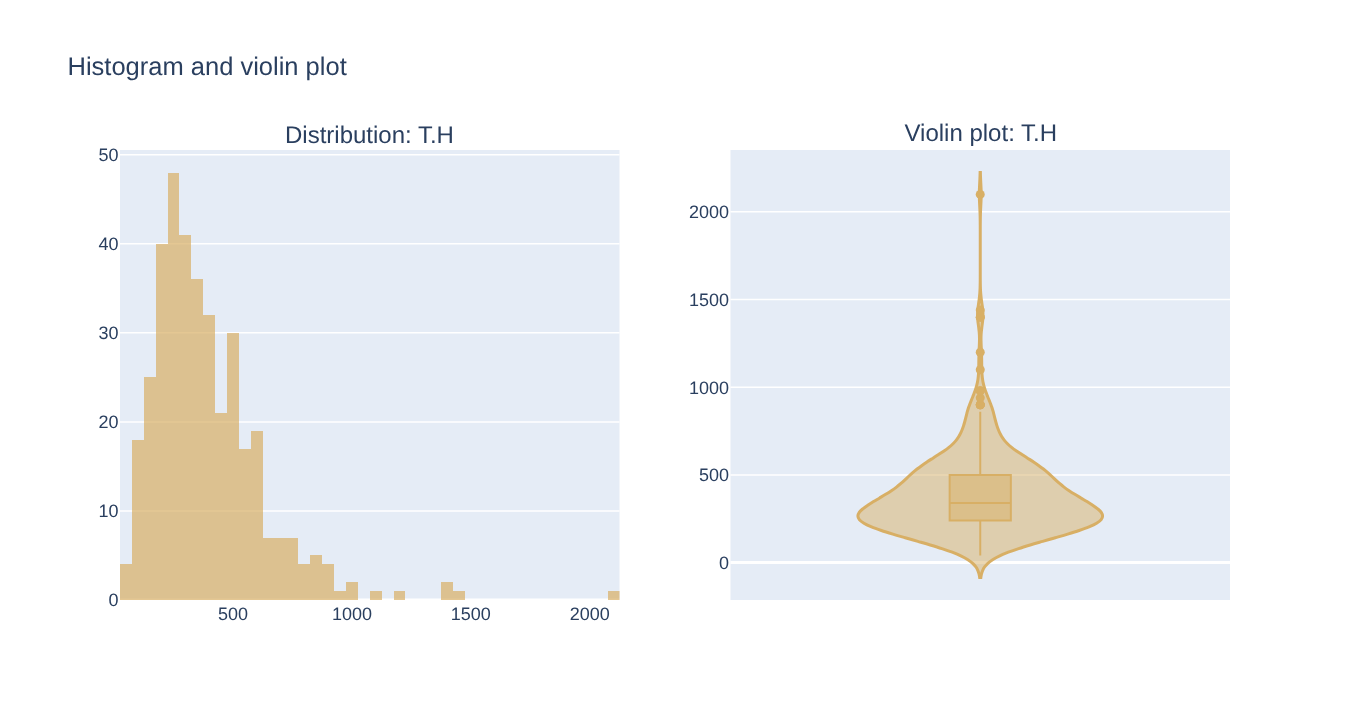

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution: T.H', 'Violin plot: T.H'])
hist_fig = px.histogram(wat, x="T.H", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="T.H", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

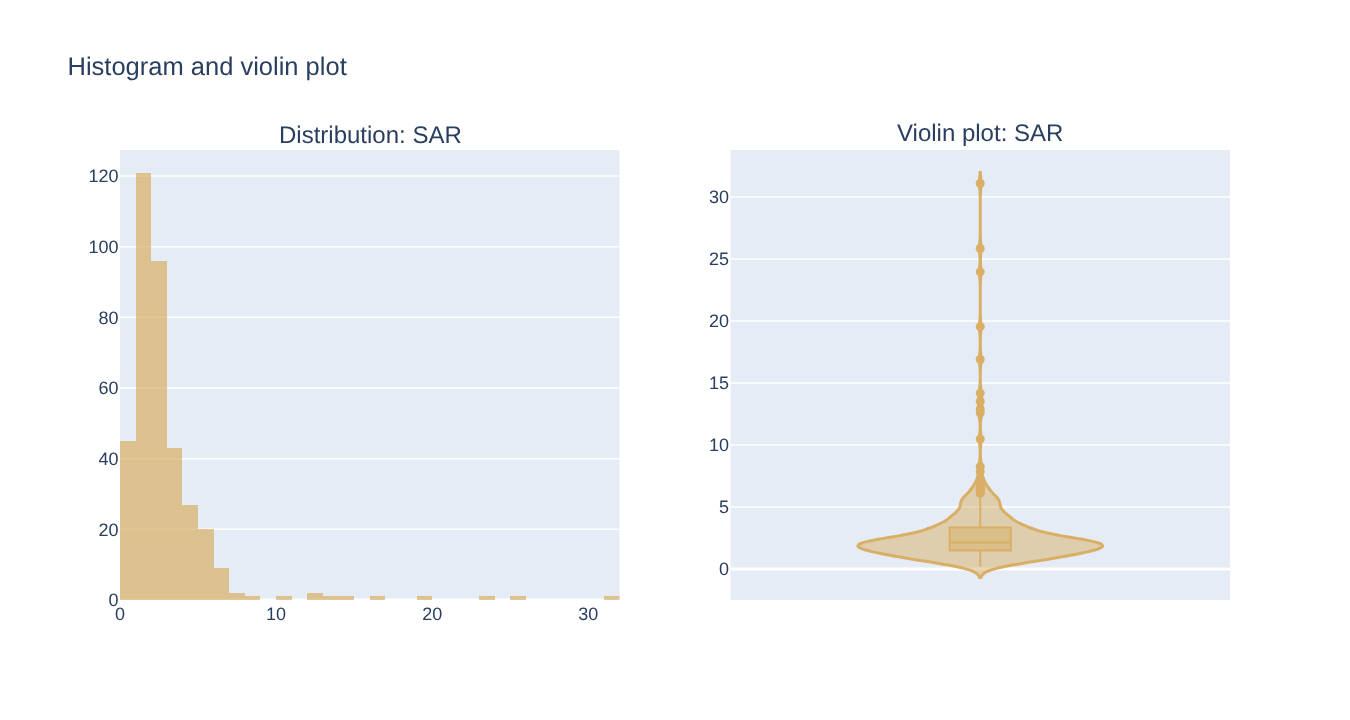

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution: SAR', 'Violin plot: SAR'])
hist_fig = px.histogram(wat, x="SAR", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="SAR", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

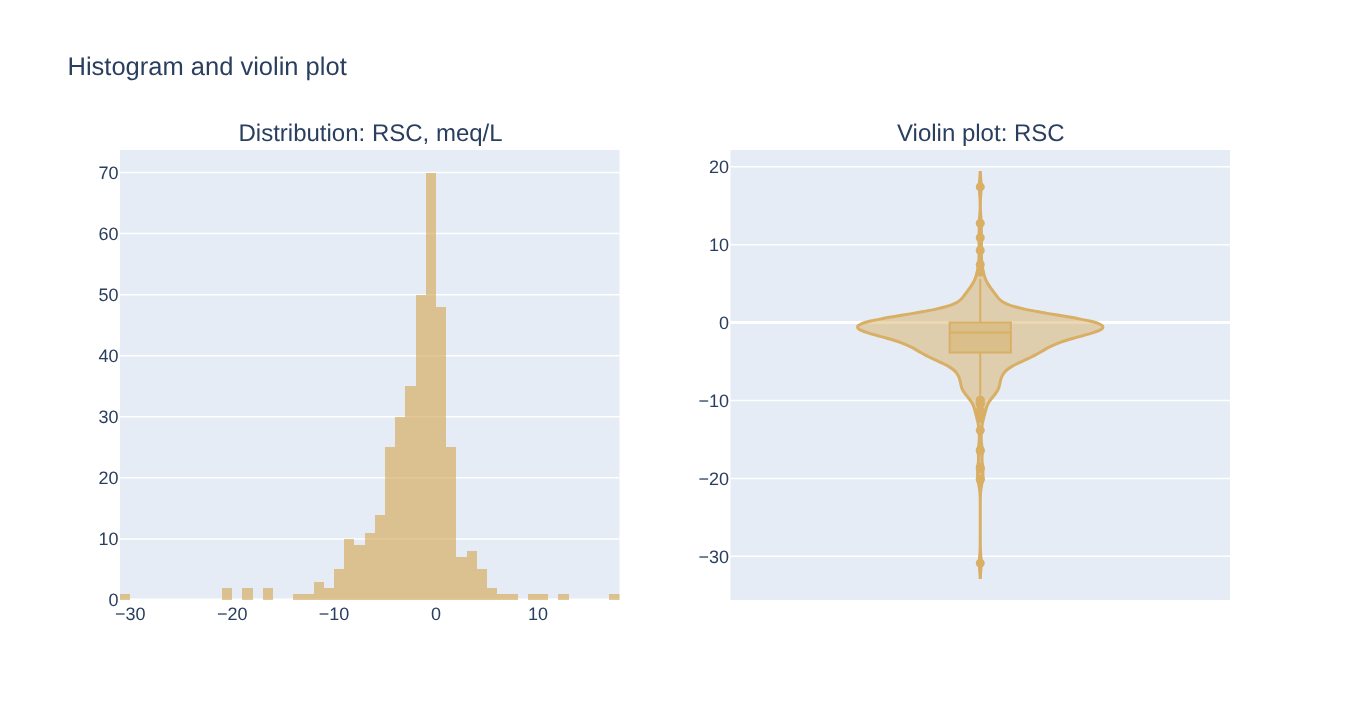

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=['Distribution: RSC  meq  / L', 'Violin plot: RSC'])
hist_fig = px.histogram(wat, x="RSC  meq  / L", nbins=60, color_discrete_sequence=colors, opacity=0.7)
fig.add_trace(hist_fig['data'][0], row=1, col=1)
violin_fig = px.violin(wat, y="RSC  meq  / L", color_discrete_sequence=colors, box=True)
fig.add_trace(violin_fig['data'][0], row=1, col=2)
fig.update_layout(showlegend=False, title_text="Histogram and violin plot")
fig.show()

**Conclusion:** the mineralisation indicators (TDS, EC, T.H, SAR, RSC) are skewed, with a long tail of high values,
which points to local geochemical anomalies and salinisation. pH is close to normal: natural buffer systems keep the
acid–base balance of the water in a narrow range.

### Location variables

Number of samples per district

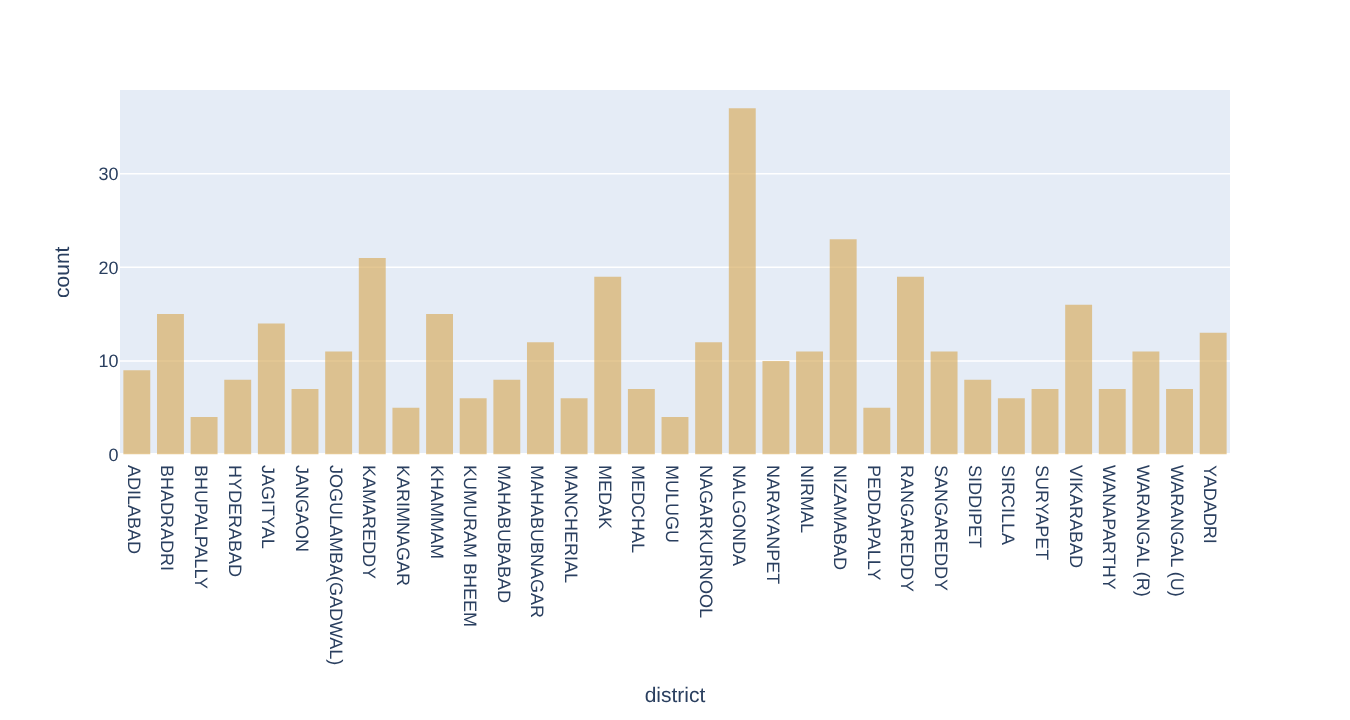

In [ ]:
hist_fig = px.histogram(wat, x="district", color_discrete_sequence=colors, opacity=0.7)
hist_fig.show()

**Conclusion:** samples are distributed very unevenly between locations: most come from a few areas, while most villages
appear only once.

### Categorical variable: water class

In [ ]:
wat_pie = pd.DataFrame(wat.groupby('Classification')['TDS'].count()).reset_index()
wat_pie

,Classification,TDS
0,C1S1,2
1,C2S1,88
2,C2S2,1
3,C3S1,234
4,C3S2,4
5,C3S3,2
6,C3S4,1
7,C4S1,21
8,C4S2,15
9,C4S3,1


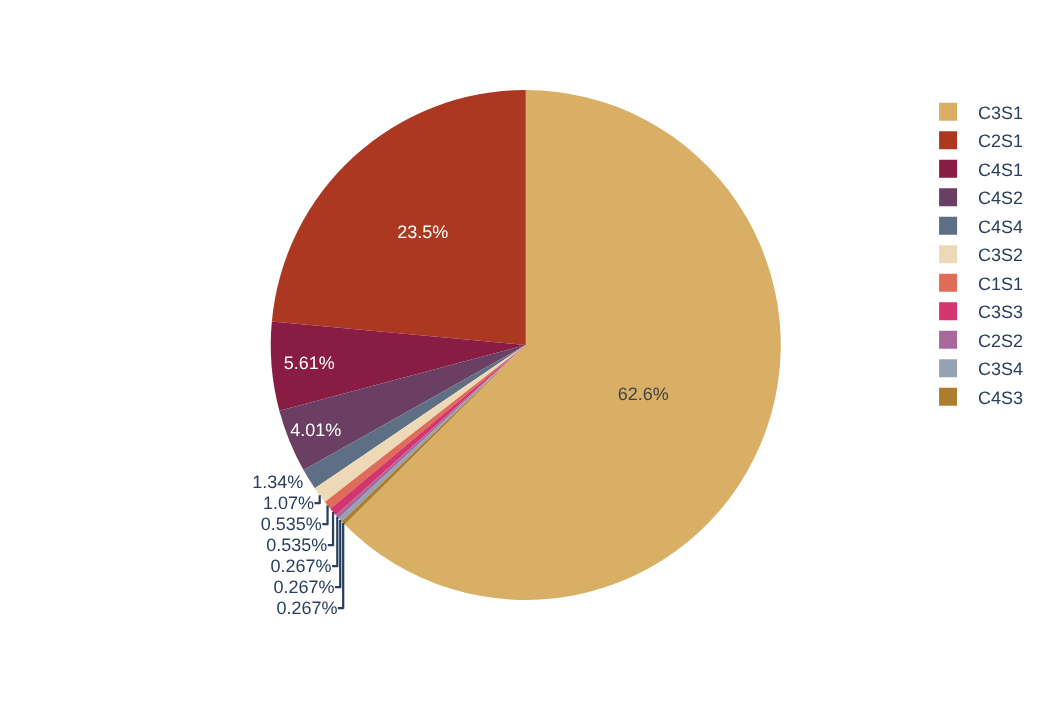

In [ ]:
fig = px.pie(wat_pie, values="TDS", names="Classification", color_discrete_sequence=colors)
fig.show()

**Conclusion:** the classes are imbalanced: most samples belong to C3S1 and C2S1, so predictions for the rare classes may be unreliable.

## Step 3. Data cleaning

In [ ]:
# Remove samples above the 95th percentile of TDS
q = wat['TDS'].quantile(0.95)
wat.loc[wat['TDS'] > q, 'TDS'] = np.nan
wat = wat.dropna(subset='TDS')

In [ ]:
wat.describe()

,lat_gis,long_gis,gwl,pH,E.C,TDS,CO3,HCO3,Cl,F,NO3,SO4,Na,K,Ca,Mg,T.H,SAR,RSC meq / L
count,355.000000,355.000000,352.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000,355.000000
mean,17.738815,78.801771,12.104773,7.900620,1194.735211,764.630535,6.985915,266.855879,160.197183,1.241915,67.787775,40.786620,109.436194,6.221380,68.822535,46.594192,363.416072,2.662815,-1.791448
std,0.842631,0.819162,8.494643,0.443002,560.957507,359.012805,18.401895,113.556750,122.415498,0.821807,75.956255,47.688035,79.534191,14.478929,42.932078,30.005717,180.689802,2.457539,3.433427
min,16.015180,77.444000,0.570000,6.810000,212.000000,135.680000,0.000000,30.000000,10.000000,0.070000,0.442900,1.000000,5.076154,0.160000,8.000000,4.862000,39.991776,0.201487,-16.493166
25%,17.150484,78.193211,5.122500,7.590000,746.000000,477.440000,0.000000,182.071159,60.000000,0.694500,20.041225,14.250000,56.970320,1.900000,40.000000,24.310000,239.930099,1.460460,-3.576706
50%,17.671300,78.597200,10.265000,7.930000,1135.000000,726.400000,0.000000,256.247806,130.000000,1.080000,45.473550,22.000000,92.842483,2.750000,56.000000,38.896000,339.901316,2.090877,-1.197697
75%,18.372871,79.360950,16.810000,8.215000,1547.500000,990.400000,0.000000,342.052876,240.000000,1.550000,90.875027,41.000000,142.126993,5.150000,88.000000,58.344000,479.868421,3.174076,0.047367
max,19.730555,80.920000,43.170000,10.440000,2783.000000,1781.120000,100.000000,664.147297,600.000000,4.970000,735.214000,327.000000,576.000000,213.700000,240.000000,199.342000,979.786184,25.837731,12.750008


## Step 4. Relations between variables

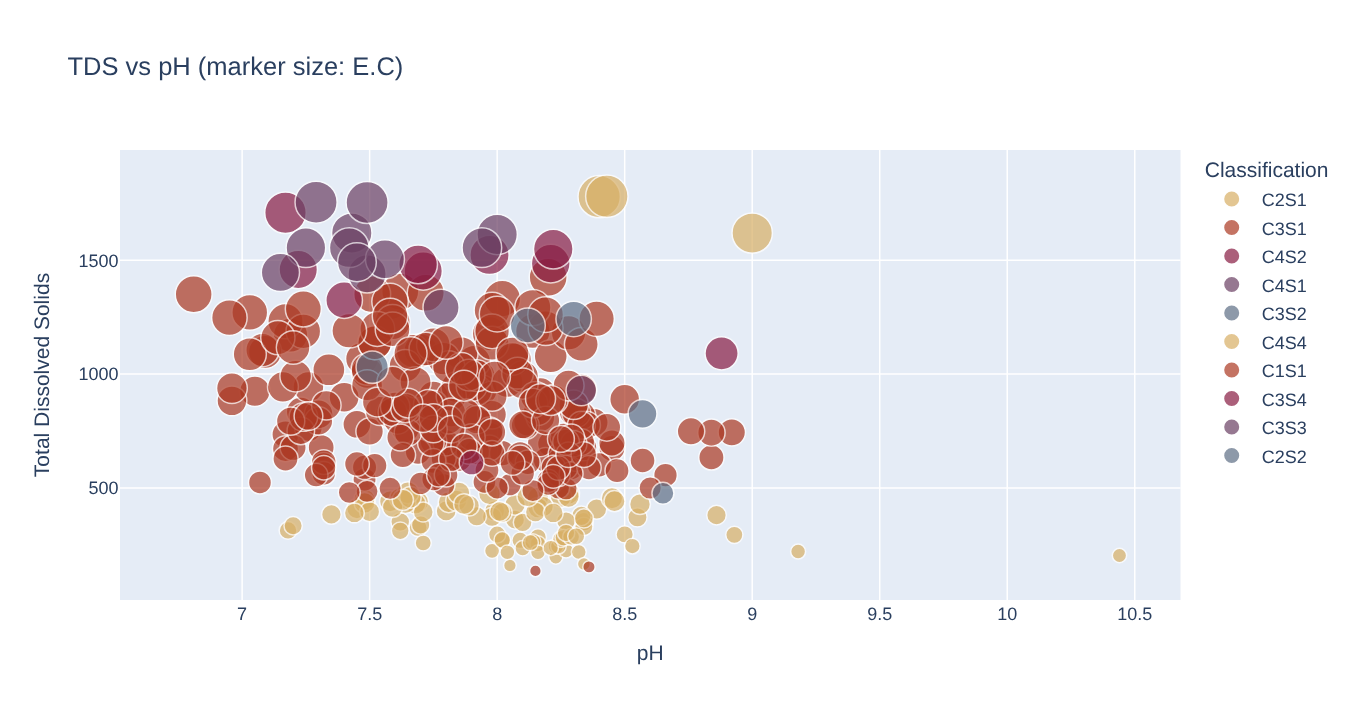

In [ ]:
fig = px.scatter(wat, x="pH", y="TDS", size="E.C", color="Classification",
                 hover_data=["village", "pH", "TDS", "E.C", "Classification"],
                 title='TDS vs pH (marker size: E.C)',
                 labels={'pH': 'pH', 'TDS': 'Total Dissolved Solids'},
                 color_discrete_sequence=colors, opacity=0.7)
fig.show()

**Conclusion:** TDS and electrical conductivity (marker size) increase together linearly, while pH stays in a narrow range.
The water classes split the plot into horizontal bands by overall mineralisation.

### Normalisation and correlation matrix

In [ ]:
wat_numeric = wat.select_dtypes(include=['float64', 'int64'])

from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler(feature_range=(0, 1))
wat_numeric_sc = pd.DataFrame(sc.fit_transform(wat_numeric), columns=wat_numeric.columns)
wat_numeric_sc.head()

,lat_gis,long_gis,gwl,pH,E.C,TDS,CO3,HCO3,Cl,F,NO3,SO4,Na,K,Ca,Mg,T.H,SAR,RSC meq / L
0,0.983244,0.310903,0.106103,0.404959,0.207312,0.207312,0.0,0.299615,0.084746,0.075510,0.056935,0.138037,0.076935,0.017983,0.172414,0.175,0.255314,0.041810,0.523010
1,0.926880,0.260884,0.106338,0.407713,0.275768,0.275768,0.0,0.315384,0.118644,0.100000,0.136391,0.205521,0.064674,0.022666,0.206897,0.300,0.382957,0.027761,0.447807
2,0.944824,0.307314,0.103521,0.242424,0.115908,0.115908,0.0,0.268077,0.033898,0.120408,0.055839,0.131902,0.069928,0.008617,0.068966,0.175,0.191470,0.043602,0.550367
3,1.000000,0.344074,0.121596,0.352617,0.081680,0.081680,0.0,0.205000,0.000000,0.104082,0.013919,0.104294,0.038401,0.003934,0.103448,0.075,0.127661,0.028345,0.564023
4,0.936779,0.405251,0.037089,0.385675,0.820303,0.820303,0.0,0.425769,0.559322,0.508163,0.174749,0.855828,0.513070,0.022666,0.206897,0.450,0.510592,0.213806,0.413645


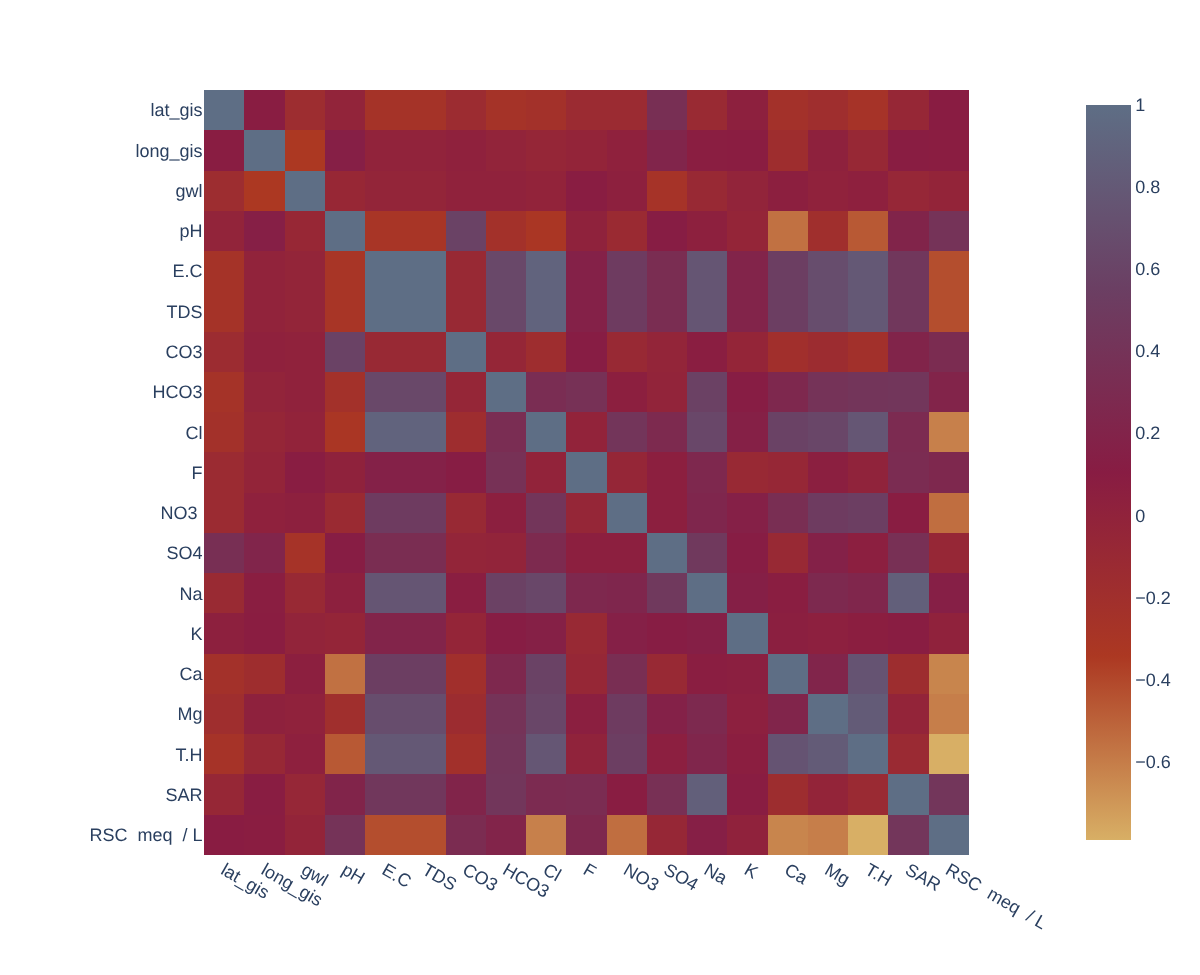

In [ ]:
fig = px.imshow(wat_numeric_sc.corr(), color_continuous_scale=colors)
fig.update_layout(width=800, height=600)
fig.show()

**Conclusion:** to remove multicollinearity, keep only one of the physically duplicated pair EC and TDS (TDS is kept),
and do not use the base ion concentrations (Ca, Mg, Na, CO₃, HCO₃) together with the indices calculated from them (T.H, SAR, RSC).

In [ ]:
wat_numeric_sc = wat_numeric_sc.drop(columns=['E.C', 'T.H'])
wat = wat.drop(columns=['E.C', 'T.H'])

## Conclusions

- The dataset contains hydrochemical data on groundwater quality in the post-monsoon period of 2018: coordinates, physical properties and ionic composition.
- Uninformative columns (`sno`, `season`, `Classification.1`) were removed during cleaning.
- The mineralisation indicators (TDS, EC, T.H, SAR) are far from normal, strongly skewed and contain outliers, mainly related to local geochemical anomalies and salinisation.
- All samples are assigned to quality classes (`Classification`), and this classification is tightly linked to conductivity and sodium content.
- Violin plots and bubble charts show the main patterns in the data, in particular the clear separation of the classes by mineralisation.
- Correlation analysis shows that many parameters are strongly correlated because of physical duplication (EC and TDS) or because they are calculated from each other (T.H, SAR, RSC from the base ions); the redundant variables are removed.